# Sales Prediction using Simple Linear Regression

**Goal:** predict product **Sales** from advertising spend, and measure how much each advertising channel (TV, Radio, Newspaper) really contributes.

**Dataset:** `advertising.csv` - 200 markets, advertising budget (in thousands of dollars) for TV, Radio and Newspaper and the resulting Sales (in thousands of units).

**Plan**
1. Load and inspect the data
2. Exploratory data analysis (distributions, correlations)
3. Compare the three channels with three simple regressions and pick the best predictor
4. Build the simple linear regression (TV -> Sales): by hand (OLS formulas) and with scikit-learn
5. Evaluate on unseen data (R2, RMSE, MAE) and check the regression assumptions
6. Confidence intervals, predictions for new budgets and a final recommendation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42

## 1. Load and inspect the data

In [2]:
df = pd.read_csv('data/advertising.csv')
print('Shape:', df.shape)
df.head()

Shape: (200, 4)

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

In [3]:
df.info()
print()
print('Missing values per column:')
print(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing values per column:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
Duplicate rows: 0

In [4]:
df.describe().round(2)

           TV   Radio  Newspaper   Sales
count  200.00  200.00     200.00  200.00
mean   147.04   23.26      30.55   15.13
std     85.85   14.85      21.78    5.28
min      0.70    0.00       0.30    1.60
25%     74.38    9.98      12.75   11.00
50%    149.75   22.90      25.75   16.00
75%    218.82   36.52      45.10   19.05
max    296.40   49.60     114.00   27.00

The data is clean: 200 rows, no missing values, no duplicates. Spend is in thousands of dollars and Sales in thousands of units.

## 2. Exploratory data analysis

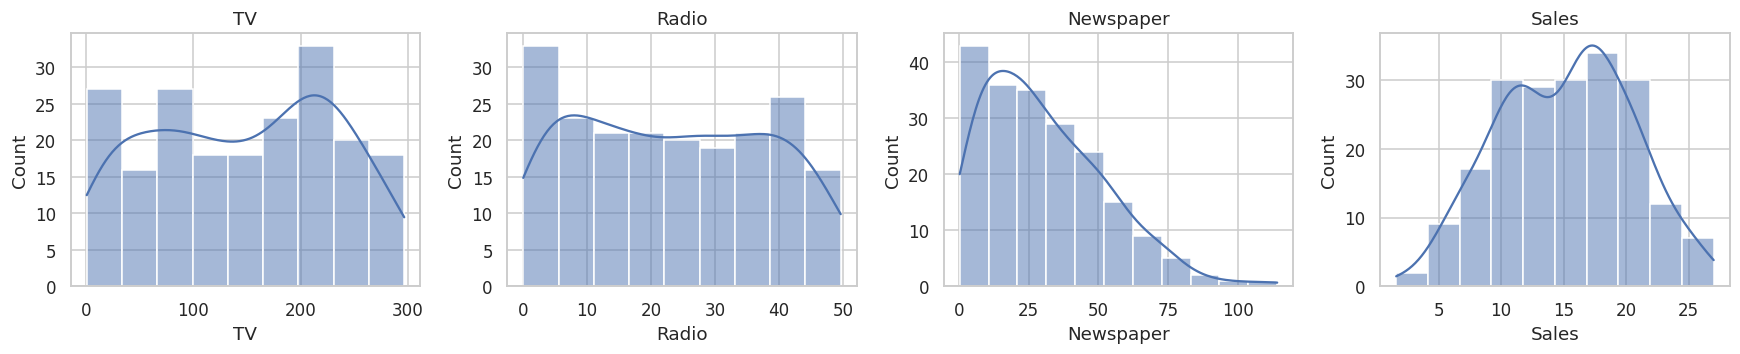

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color='#4C72B0')
    ax.set_title(col)
plt.tight_layout()

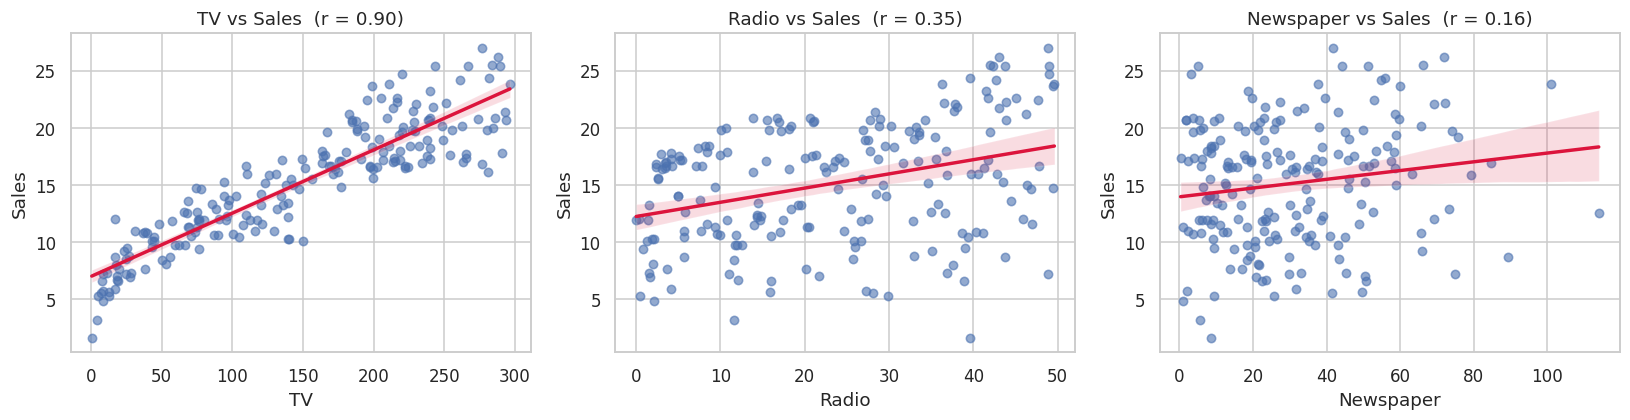

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['TV', 'Radio', 'Newspaper']):
    sns.regplot(x=col, y='Sales', data=df, ax=ax, scatter_kws={'alpha': .6, 's': 30}, line_kws={'color': 'crimson'})
    r = df[col].corr(df['Sales'])
    ax.set_title(f'{col} vs Sales  (r = {r:.2f})')
plt.tight_layout()

TV           0.901208
Radio        0.349631
Newspaper    0.157960
Name: Sales, dtype: float64

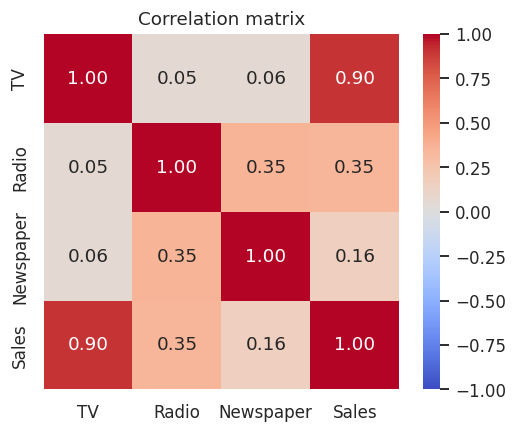

In [7]:
corr = df.corr()
plt.figure(figsize=(5.5, 4.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix')
corr['Sales'].drop('Sales').sort_values(ascending=False)

**Observations**
- TV has by far the strongest linear relationship with Sales (r = 0.90); Radio is weak-to-moderate (r = 0.35) and Newspaper is weak (r = 0.16).
- The TV vs Sales scatter is close to a straight line, which is exactly what simple linear regression assumes.
- The three budgets are almost uncorrelated with TV (r = 0.05-0.06), but Radio and Newspaper are mildly correlated with each other (r = 0.35), so part of Newspaper's small signal may simply be borrowed from Radio.

## 3. Which single channel predicts Sales best?

Simple linear regression uses **one** predictor. Fit one regression per channel and compare how much of the variation in Sales each explains (R2) and whether the slope is statistically significant.

In [8]:
rows = []
for col in ['TV', 'Radio', 'Newspaper']:
    res = stats.linregress(df[col], df['Sales'])
    rows.append({'Predictor': col, 'Slope': res.slope, 'Intercept': res.intercept,
                 'R2': res.rvalue ** 2, 'p-value (slope)': res.pvalue, 'Std. error (slope)': res.stderr})
channel_table = pd.DataFrame(rows).set_index('Predictor').sort_values('R2', ascending=False)
channel_table.round(4)

            Slope  Intercept      R2  p-value (slope)  Std. error (slope)
Predictor                                                                
TV         0.0555     6.9748  0.8122           0.0000              0.0019
Radio      0.1244    12.2357  0.1222           0.0000              0.0237
Newspaper  0.0383    13.9595  0.0250           0.0255              0.0170

TV explains roughly **81%** of the variation in Sales on its own, Radio only about 12% and Newspaper about 3%. All slopes are positive, but TV is far stronger, so the simple linear regression below uses **TV** as the predictor.

## 4. Simple linear regression: Sales = b0 + b1 x TV

### 4.1 Train / test split
Hold out 20% of the markets that the model never sees while fitting.

In [9]:
X = df[['TV']]
y = df['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train rows:', len(X_train), '| Test rows:', len(X_test))

Train rows: 160 | Test rows: 40

### 4.2 The maths by hand (Ordinary Least Squares)

For one predictor the best-fit line has a closed form:

- slope  b1 = Cov(x, y) / Var(x)
- intercept b0 = mean(y) - b1 x mean(x)

In [10]:
x = X_train['TV'].values
t = y_train.values
b1_manual = np.cov(x, t, ddof=1)[0, 1] / np.var(x, ddof=1)
b0_manual = t.mean() - b1_manual * x.mean()
print(f'Manual OLS  ->  intercept b0 = {b0_manual:.4f},  slope b1 = {b1_manual:.4f}')

Manual OLS  ->  intercept b0 = 7.0071,  slope b1 = 0.0555

### 4.3 The same model with scikit-learn

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)
print(f'scikit-learn ->  intercept b0 = {model.intercept_:.4f},  slope b1 = {model.coef_[0]:.4f}')
print('Same as manual OLS:', np.isclose(model.intercept_, b0_manual) and np.isclose(model.coef_[0], b1_manual))

scikit-learn ->  intercept b0 = 7.0071,  slope b1 = 0.0555
Same as manual OLS: True

**Reading the equation**

`Sales = b0 + b1 x TV` - for every extra **1 thousand dollars** of TV budget, expected sales rise by about **b1 thousand units** (about 55 extra units per 1,000 dollars). The intercept is the expected sales with zero TV advertising (the baseline from other factors).

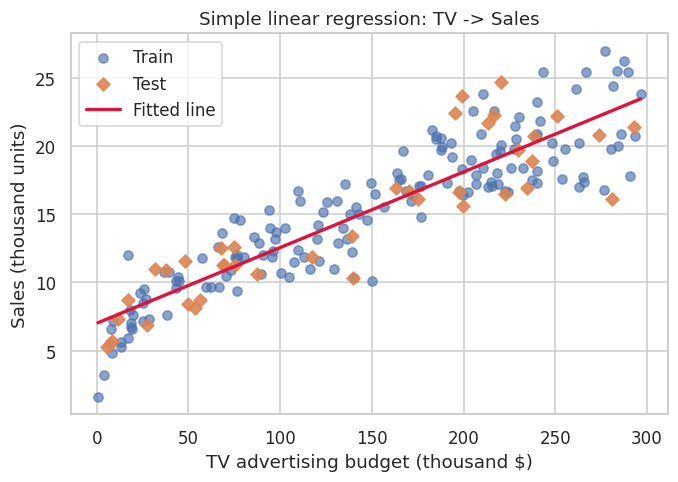

In [12]:
plt.figure(figsize=(7, 4.5))
plt.scatter(X_train, y_train, alpha=.65, label='Train', color='#4C72B0')
plt.scatter(X_test, y_test, alpha=.9, label='Test', color='#DD8452', marker='D')
line_x = np.linspace(df['TV'].min(), df['TV'].max(), 100).reshape(-1, 1)
plt.plot(line_x, model.predict(pd.DataFrame(line_x, columns=['TV'])), color='crimson', lw=2.2, label='Fitted line')
plt.xlabel('TV advertising budget (thousand $)')
plt.ylabel('Sales (thousand units)')
plt.title('Simple linear regression: TV -> Sales')
plt.legend()

## 5. Model evaluation

In [13]:
def report(name, y_true, y_pred):
    return {'Set': name,
            'R2': r2_score(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred)}

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
metrics = pd.DataFrame([report('Train', y_train, pred_train), report('Test', y_test, pred_test)]).set_index('Set')
metrics.round(3)

          R2   RMSE    MAE
Set                       
Train  0.813  2.236  1.801
Test   0.803  2.470  1.950

In [14]:
cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print('5-fold cross-validated R2 scores:', cv.round(3))
print(f'Mean R2 = {cv.mean():.3f}  (+/- {cv.std():.3f})')
print(f'Average sales = {y.mean():.2f}; test RMSE is about {np.sqrt(mean_squared_error(y_test, pred_test)) / y.mean():.0%} of the average')

5-fold cross-validated R2 scores: [0.787 0.839 0.833 0.76  0.798]
Mean R2 = 0.804  (+/- 0.029)
Average sales = 15.13; test RMSE is about 16% of the average

Train and test scores are close and the cross-validation scores are stable, so the model **generalises** and is not overfitted. A single predictor already gives a test R2 of about 0.80, with an average absolute error (MAE) of roughly 2 thousand units and an RMSE of about 2.5 thousand units (around 16% of average sales).

### 5.1 Checking the regression assumptions
Linear regression is only trustworthy if the residuals (actual - predicted) behave: centred on zero, no pattern against the fitted values, roughly normal.

Mean residual: -0.175  (should be near 0)
Shapiro-Wilk normality test: W = 0.965, p = 0.239

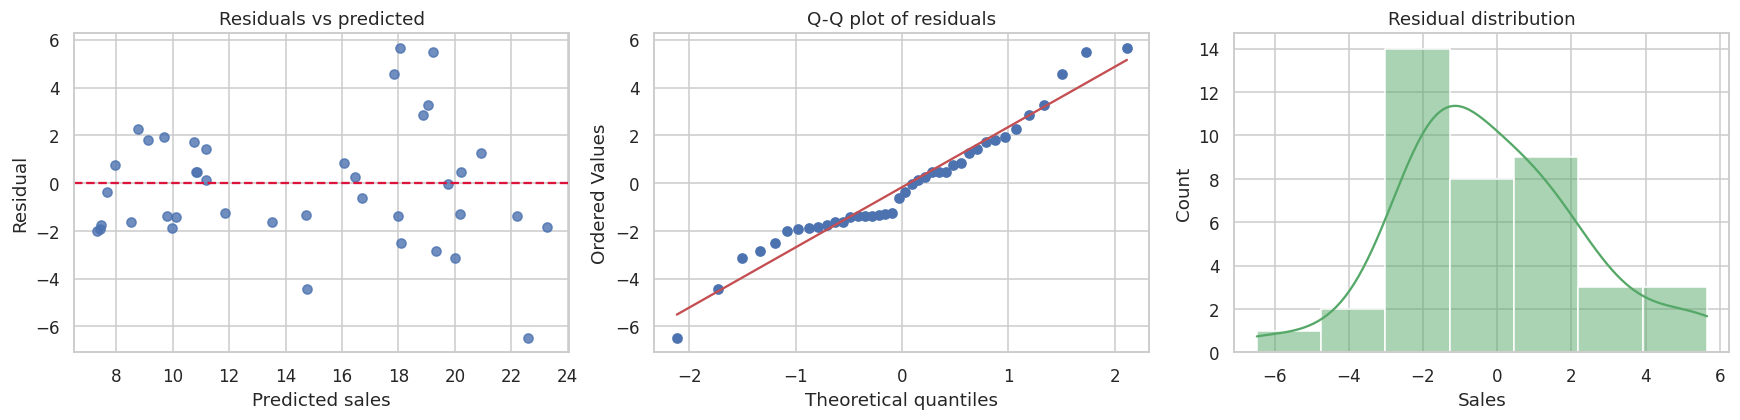

In [15]:
resid = y_test - pred_test
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(pred_test, resid, alpha=.8, color='#4C72B0')
axes[0].axhline(0, color='crimson', ls='--')
axes[0].set_xlabel('Predicted sales'); axes[0].set_ylabel('Residual'); axes[0].set_title('Residuals vs predicted')

stats.probplot(resid, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot of residuals')

sns.histplot(resid, kde=True, ax=axes[2], color='#55A868')
axes[2].set_title('Residual distribution')
plt.tight_layout()

shapiro = stats.shapiro(resid)
print(f'Mean residual: {resid.mean():.3f}  (should be near 0)')
print(f'Shapiro-Wilk normality test: W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.3f}')

**What the diagnostics say**
- Residuals are centred close to zero (mean about -0.2) and the Shapiro-Wilk test (p about 0.24) gives no evidence against normality; the Q-Q plot follows the line except for a few points in the tails.
- With only 40 test points, patterns are hard to judge, but the fitted-line plot shows Sales scattering more widely around the line at high TV budgets (mild **heteroscedasticity**). This is a normal limit of a one-variable model and a reason to try more predictors (section 7).

## 6. Confidence intervals and predictions for new budgets
Fit on all 200 rows to get the final, best-supported estimates, then quantify the uncertainty.

In [16]:
final = stats.linregress(df['TV'], df['Sales'])
n = len(df)
t_crit = stats.t.ppf(0.975, n - 2)
ci_slope = (final.slope - t_crit * final.stderr, final.slope + t_crit * final.stderr)
print(f'Final model: Sales = {final.intercept:.3f} + {final.slope:.4f} x TV')
print(f'R2 = {final.rvalue ** 2:.3f}   p-value of slope = {final.pvalue:.2e}')
print(f'95% confidence interval for the slope: ({ci_slope[0]:.4f}, {ci_slope[1]:.4f})')

Final model: Sales = 6.975 + 0.0555 x TV
R2 = 0.812   p-value of slope = 7.93e-74
95% confidence interval for the slope: (0.0517, 0.0592)

In [17]:
# prediction intervals for a few planned TV budgets (thousand $)
resid_all = df['Sales'] - (final.intercept + final.slope * df['TV'])
s = np.sqrt((resid_all ** 2).sum() / (n - 2))
xbar, sxx = df['TV'].mean(), ((df['TV'] - df['TV'].mean()) ** 2).sum()
budgets = np.array([50, 100, 150, 200, 250, 300])
pred = final.intercept + final.slope * budgets
half = t_crit * s * np.sqrt(1 + 1 / n + (budgets - xbar) ** 2 / sxx)
forecast = pd.DataFrame({'TV budget (k$)': budgets, 'Predicted sales (k units)': pred.round(2),
                         '95% lower': (pred - half).round(2), '95% upper': (pred + half).round(2)})
forecast

   TV budget (k$)  Predicted sales (k units)  95% lower  95% upper
0              50                       9.75       5.20      14.30
1             100                      12.52       7.98      17.06
2             150                      15.29      10.76      19.83
3             200                      18.07      13.52      22.61
4             250                      20.84      16.29      25.40
5             300                      23.61      19.04      28.19

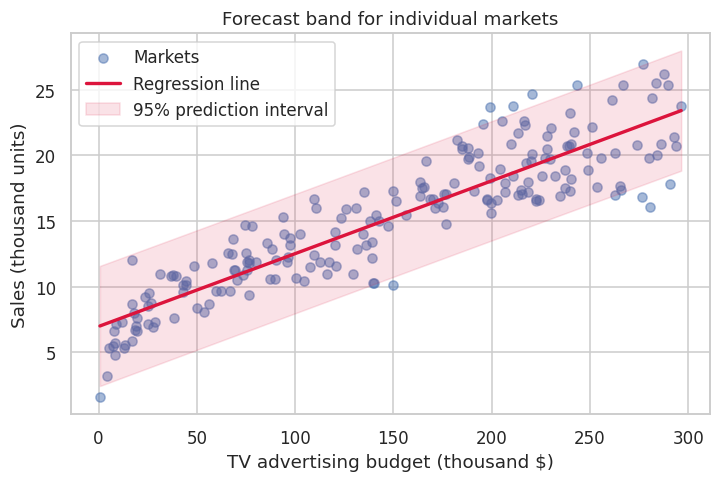

In [18]:
plt.figure(figsize=(7.5, 4.5))
plt.scatter(df['TV'], df['Sales'], alpha=.5, color='#4C72B0', label='Markets')
xs = np.linspace(df['TV'].min(), df['TV'].max(), 200)
ys = final.intercept + final.slope * xs
h = t_crit * s * np.sqrt(1 + 1 / n + (xs - xbar) ** 2 / sxx)
plt.plot(xs, ys, color='crimson', lw=2.2, label='Regression line')
plt.fill_between(xs, ys - h, ys + h, color='crimson', alpha=.12, label='95% prediction interval')
plt.xlabel('TV advertising budget (thousand $)'); plt.ylabel('Sales (thousand units)')
plt.title('Forecast band for individual markets'); plt.legend()

## 7. Extension: does adding Radio and Newspaper help?
The task asks for *simple* regression, but it is worth checking how much a multiple regression would improve things, using the same split.

In [19]:
compare = []
for name, cols in [('TV only (simple)', ['TV']), ('TV + Radio', ['TV', 'Radio']),
                   ('TV + Radio + Newspaper', ['TV', 'Radio', 'Newspaper'])]:
    m = LinearRegression().fit(df.loc[X_train.index, cols], y_train)
    p = m.predict(df.loc[X_test.index, cols])
    compare.append({'Model': name, 'Test R2': r2_score(y_test, p), 'Test RMSE': np.sqrt(mean_squared_error(y_test, p)),
                    'Test MAE': mean_absolute_error(y_test, p)})
pd.DataFrame(compare).set_index('Model').round(3)

                        Test R2  Test RMSE  Test MAE
Model                                               
TV only (simple)          0.803      2.470     1.950
TV + Radio                0.908      1.687     1.267
TV + Radio + Newspaper    0.906      1.705     1.275

In [20]:
multi = LinearRegression().fit(df[['TV', 'Radio', 'Newspaper']], df['Sales'])
pd.Series(multi.coef_, index=['TV', 'Radio', 'Newspaper'], name='Coefficient (units per $1k)').round(4)

TV           0.0544
Radio        0.1070
Newspaper    0.0003
Name: Coefficient (units per $1k), dtype: float64

## 8. Conclusions

1. **TV is the single best predictor of Sales** - on its own it explains about 81% of the variation in Sales, versus about 12% for Radio and 3% for Newspaper.
2. The simple model is `Sales = b0 + b1 x TV`: every extra **$1,000** of TV budget is associated with about **55 more units** sold. The slope is highly significant (p-value far below 0.001) and its 95% confidence interval is narrow.
3. The model generalises: train, test and 5-fold cross-validation scores agree.
4. Residual checks show roughly normal errors, with somewhat more scatter at high budgets, so individual predictions there are less certain (see the prediction band).
5. Adding **Radio** improves accuracy clearly (test R2 rises from 0.80 to 0.91, RMSE from 2.47 to 1.69) while **Newspaper adds nothing** (R2 stays 0.91 and its coefficient is about zero). A useful budgeting insight: favour TV and Radio over Newspaper.

**Limitations:** the data only shows association, not proof of causation; 200 markets is small; the relationship may saturate at very high budgets; the interaction between TV and Radio is not modelled.